In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets,transforms
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
import numpy as np

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
print(os.listdir('/content/drive/MyDrive'))

['23-50723-1.pdf', 'Diabetes Prediction JOURNAL', 'Thesis', 'Copy of Screen Recording 2026-11-03 134259.mp4', 'Colab Notebooks', 'Sugarcane Leaf Disease Dataset']


In [4]:
dataset_path = '/content/drive/MyDrive/Sugarcane Leaf Disease Dataset'
print(os.listdir(dataset_path))

['RedRot', 'Rust', 'Mosaic', 'Yellow', 'Healthy']


In [5]:
from collections import Counter
import os

original_path = dataset_path

for class_name in os.listdir(original_path):
    class_path = os.path.join(original_path, class_name)

    if os.path.isdir(class_path):
        images = os.listdir(class_path)
        print(f"{class_name}: {len(images)} images")

RedRot: 518 images
Rust: 514 images
Mosaic: 462 images
Yellow: 505 images
Healthy: 522 images


In [6]:
from PIL import Image

class_name = os.listdir(original_path)[0]
class_path = os.path.join(original_path, class_name)

image_name = os.listdir(class_path)[0]
image_path = os.path.join(class_path, image_name)

img = Image.open(image_path)

print("Class:", class_name)
print("Image:", image_name)
print("Size:", img.size)
print("Mode:", img.mode)

Class: RedRot
Image: redrot (230).jpeg
Size: (485, 713)
Mode: RGB


In [7]:
split_base = '/content/drive/MyDrive/Sugarcane Leaf Disease Dataset/Split Dataset'

for split in ['train', 'val', 'test']:
    for class_name in os.listdir(original_path):
        os.makedirs(
            os.path.join(split_base, split, class_name),
            exist_ok=True
        )

print("Train, Validation and Test folders created.")

Train, Validation and Test folders created.


In [8]:
import random
import shutil

class_name = 'RedRot'

source_class_path = os.path.join(original_path, class_name)

images = [
    img for img in os.listdir(source_class_path)
    if img.lower().endswith(('.png', '.jpg', '.jpeg'))
]

random.seed(42)
random.shuffle(images)

train_count = int(len(images) * 0.70)
val_count = int(len(images) * 0.10)

train_images = images[:train_count]
val_images = images[train_count:train_count + val_count]
test_images = images[train_count + val_count:]

print("Total:", len(images))
print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))

Total: 518
Train: 362
Validation: 51
Test: 105


In [10]:
for class_name in os.listdir(original_path):

    source_class_path = os.path.join(original_path, class_name)

    images = [
        img for img in os.listdir(source_class_path)
        if img.lower().endswith(('.png', '.jpg', '.jpeg'))
    ]

    random.seed(42)
    random.shuffle(images)

    train_count = int(len(images) * 0.70)
    val_count = int(len(images) * 0.10)

    train_images = images[:train_count]
    val_images = images[train_count:train_count + val_count]
    test_images = images[train_count + val_count:]

    for img in train_images:
        shutil.copy(
            os.path.join(source_class_path, img),
            os.path.join(split_base, 'train', class_name, img)
        )

    for img in val_images:
        shutil.copy(
            os.path.join(source_class_path, img),
            os.path.join(split_base, 'val', class_name, img)
        )

    for img in test_images:
        shutil.copy(
            os.path.join(source_class_path, img),
            os.path.join(split_base, 'test', class_name, img)
        )

    print(f"{class_name}: Train={len(train_images)}, Val={len(val_images)}, Test={len(test_images)}")

RedRot: Train=362, Val=51, Test=105
Rust: Train=359, Val=51, Test=104
Mosaic: Train=323, Val=46, Test=93
Yellow: Train=353, Val=50, Test=102
Healthy: Train=365, Val=52, Test=105
Split Dataset: Train=0, Val=0, Test=0


In [12]:
class_names = ['RedRot', 'Rust', 'Mosaic', 'Yellow', 'Healthy']

for split in ['train', 'val', 'test']:
    print(f"\n{split.upper()} Dataset:")

    for class_name in class_names:
        folder_path = os.path.join(split_base, split, class_name)

        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        print(f"{class_name}: {len(images)}")


TRAIN Dataset:
RedRot: 362
Rust: 359
Mosaic: 323
Yellow: 353
Healthy: 365

VAL Dataset:
RedRot: 51
Rust: 51
Mosaic: 46
Yellow: 50
Healthy: 52

TEST Dataset:
RedRot: 105
Rust: 104
Mosaic: 93
Yellow: 102
Healthy: 105


In [13]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

In [14]:
from torchvision import datasets, transforms

train_path = os.path.join(split_base, 'train')

temp_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

temp_train_dataset = datasets.ImageFolder(
    root=train_path,
    transform=temp_transform
)

print("Number of training images:", len(temp_train_dataset))
print("Classes:", temp_train_dataset.classes)

Number of training images: 1762
Classes: ['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']


In [15]:
import torch

channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
num_pixels = 0

for images, _ in DataLoader(temp_train_dataset,batch_size=32,shuffle=False):
    # images shape: [batch, 3, 224, 224]
    channel_sum += images.sum(dim=[0, 2, 3])
    channel_squared_sum += (images ** 2).sum(dim=[0, 2, 3])

    num_pixels += images.size(0) * images.size(2) * images.size(3)

mean = channel_sum / num_pixels

std = torch.sqrt((channel_squared_sum / num_pixels) - (mean ** 2))

print("Mean:", mean)
print("Std :", std)

Mean: tensor([0.4988, 0.5285, 0.3801])
Std : tensor([0.1900, 0.1905, 0.1958])


In [16]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4988, 0.5285, 0.3801],
        std=[0.1900, 0.1905, 0.1958]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4988, 0.5285, 0.3801],
        std=[0.1900, 0.1905, 0.1958]
    )
])

In [17]:
import os
import shutil

for split in ['train', 'val', 'test']:

    extra_folder = os.path.join(split_base, split, 'Split Dataset')

    if os.path.exists(extra_folder):
        shutil.rmtree(extra_folder)


In [18]:
train_dataset = datasets.ImageFolder(root=os.path.join(split_base, 'train'),transform=train_transform)
val_dataset = datasets.ImageFolder(root=os.path.join(split_base, 'val'),transform=val_test_transform)
test_dataset = datasets.ImageFolder(root=os.path.join(split_base, 'test'),transform=val_test_transform)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print("\nClasses:", train_dataset.classes)
print("Class to index:", train_dataset.class_to_idx)

Train: 1762
Validation: 250
Test: 509

Classes: ['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']
Class to index: {'Healthy': 0, 'Mosaic': 1, 'RedRot': 2, 'Rust': 3, 'Yellow': 4}


In [19]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)

val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False)

test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 56
Validation batches: 8
Test batches: 16


In [20]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: tensor([3, 0, 4, 0, 1, 0, 4, 2, 2, 4, 4, 1, 4, 3, 2, 2, 4, 0, 4, 4, 4, 3, 1, 2,
        2, 2, 0, 0, 2, 1, 1, 2])


In [30]:

import torch.nn as nn

class SugarcaneCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3,40,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(40,70,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(70,100,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4,4))
        )

        # Classification
        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(100*4*4,256),
            nn.ReLU(),
            nn.Linear(256,5)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x


In [32]:
model = SugarcaneCNN().to(device)

print(model)

SugarcaneCNN(
  (features): Sequential(
    (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(40, 70, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(70, 100, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1600, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=5, bias=True)
  )
)


In [33]:
total_params = sum(p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)

Trainable parameters: 500631


In [34]:
criterion = nn.CrossEntropyLoss()
print(criterion)

CrossEntropyLoss()


In [35]:
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [36]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [37]:
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [38]:
epochs = 50
print("Epochs:", epochs)

Epochs: 50


In [39]:
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(epochs):

    train_loss, train_accuracy = train_one_epoch(model,train_loader,criterion,optimizer,device)
    val_loss, val_accuracy = validate(model,val_loader,criterion,device)

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/50] Train Loss: 1.3828 | Train Accuracy: 38.02% | Validation Loss: 1.0300 | Validation Accuracy: 55.60%
Epoch [2/50] Train Loss: 1.0443 | Train Accuracy: 55.79% | Validation Loss: 1.0292 | Validation Accuracy: 57.60%
Epoch [3/50] Train Loss: 0.8901 | Train Accuracy: 63.39% | Validation Loss: 0.6571 | Validation Accuracy: 74.40%
Epoch [4/50] Train Loss: 0.7464 | Train Accuracy: 70.03% | Validation Loss: 0.6376 | Validation Accuracy: 71.60%
Epoch [5/50] Train Loss: 0.6246 | Train Accuracy: 75.48% | Validation Loss: 0.5313 | Validation Accuracy: 79.20%
Epoch [6/50] Train Loss: 0.5234 | Train Accuracy: 79.91% | Validation Loss: 0.5434 | Validation Accuracy: 81.20%
Epoch [7/50] Train Loss: 0.5548 | Train Accuracy: 78.94% | Validation Loss: 0.4399 | Validation Accuracy: 86.00%
Epoch [8/50] Train Loss: 0.4006 | Train Accuracy: 84.79% | Validation Loss: 0.4247 | Validation Accuracy: 83.60%
Epoch [9/50] Train Loss: 0.3354 | Train Accuracy: 87.51% | Validation Loss: 0.4342 | Validation 

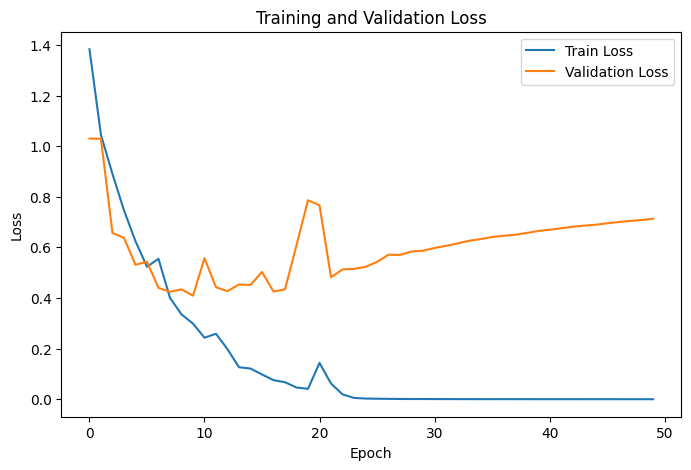

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

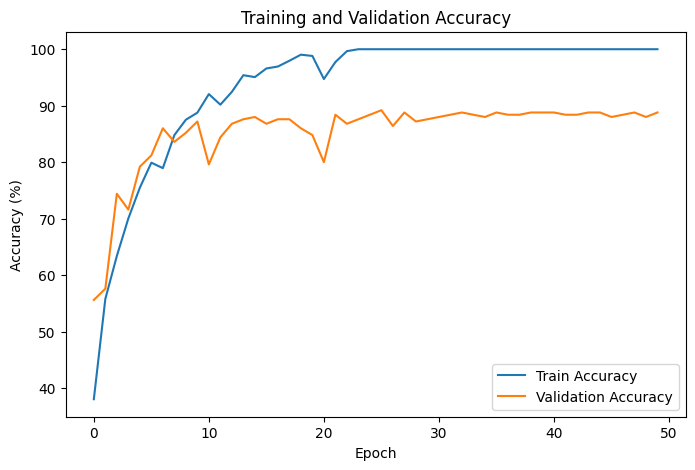

In [41]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.show()
